## Recomendación: Híbrido y evaluación final

- **Híbrido ponderado:** $S(u, i) = w \cdot \tilde S_{ALS}(u, i) + (1 - w) \cdot \tilde S_{CB}(u, i)$, con $\tilde S$ normalizado min-max por entidad

- **Respaldo por contenido:** si el proveedor **nunca ganó** en train, ALS no lo conoce y su puntaje es solo el de contenido, $S(u, i) = \tilde S_{CB}(u, i)$; sin respaldo recibiría 0 en la parte de ALS y nunca podría superar $1 - w$

- `w` se calibra en el split **ajuste** (2023 → 2024); el hold-out 2025 se usa una sola vez

- Se compara además con **fusión por rangos** (RRF), que no necesita normalizar puntajes

- Responde **PQ3.2**: cuánto del sesgo de popularidad corrige el híbrido y a qué costo en acierto

- Las siguientes conclusiones con cifras se calculan en celdas `display(Markdown(...))`

### Constantes

- `RANGO_W`: pesos de ALS que se prueban (0 = solo contenido, 1 = solo ALS)

- `K_RRF`: constante de la fusión por rangos, $\sum_m 1 / (K_{RRF} + \text{rank}_m)$ (60 es el valor usual)

- `W_WEB`: pesos para los que se exportan recomendaciones a la app (Parte VII)

In [1]:
RANGO_W = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
K_RRF = 60
W_WEB = [0.0, 0.25, 0.5, 0.75, 1.0]

### Utilidades

In [2]:
NOTEBOOK = "d_hibrido_evaluacion"
%run ../funciones.ipynb
%run funciones.ipynb

/opt/conda/lib/python3.11/site-packages/nbformat/__init__.py:93: MissingIDFieldWarning: Code cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
from IPython.display import Markdown, display

config = leer_config(); P_ALS, P_CB = config["als"], config["contenido"]
ctx = {s: contexto(s) for s in SPLITS}
cands = {s: {m: leer_cand(s, m) for m in ["als", "contenido"]} for s in SPLITS}
cands["final"] |= {m: leer_cand("final", m) for m in ["popularidad_global", "popularidad_familia"]}
print("ALS:", P_ALS, "| contenido:", P_CB)

ALS: {'rank': 100, 'reg': 1.0, 'alpha': 10.0, 'senal': 'r_mix'} | contenido: {'dim': 512, 'min_df': 5, 'max_df': 0.3, 'max_feat': 50000, 'gamma': 0.5, 'prof': 2000, 'M': 16, 'ef_construction': 200, 'espacio_indice': 'cosine'}


---
### **1. Puntajes completos de los candidatos**

- Candidatos de una entidad = top-200 de ALS ∪ top-200 de contenido

- Un candidato que trajo solo un modelo necesita el puntaje del **otro**:
    - **Contenido** de un candidato de ALS: producto interno con los vectores guardados en `c_contenido_ann` (coseno × actividad^γ); todo ganador de train está en el catálogo de contenido
    - **ALS** de un candidato de contenido: $x_u^\top y_i$ si el proveedor ganó en train; si **nunca ganó**, ALS no tiene factor y recibe el **mínimo** de la entidad (tras normalizar, 0)

- ALS se reajusta aquí con los parámetros y la semilla elegidos en `b_baseline_als` (`b` guarda candidatos, no factores)

In [5]:
ratings = {s: spark.read.parquet(str(datos_dir / f"{s}_train")) for s in SPLITS}

als_f, vec = {}, {}
for s, c in ctx.items():
    U, V, _ = entrenar_als(ratings[s], c, P_ALS["rank"], P_ALS["reg"], P_ALS["alpha"], P_ALS["senal"])
    als_f[s] = (U, V, pd.Series(np.arange(c.n_u), index=c.key_e), pd.Series(np.arange(c.n_i), index=c.key_p))
    vp = pd.read_parquet(datos_dir / f"{s}_contenido_proveedor"); ve = pd.read_parquet(datos_dir / f"{s}_contenido_entidad")
    vec[s] = (np.vstack(ve.vec.to_numpy()).astype(np.float32), np.vstack(vp.vec.to_numpy()).astype(np.float32),
              pd.Series(np.arange(len(ve)), index=ve.entidad_key), pd.Series(np.arange(len(vp)), index=vp.proveedor_key))
    print(f"{s}: ALS {als_f[s][0].shape} × {als_f[s][1].shape} | contenido {vec[s][0].shape} × {vec[s][1].shape}")

ajuste: ALS (2619, 100) × (33828, 100) | contenido (2619, 512) × (109323, 512)


final: ALS (2860, 100) × (61145, 100) | contenido (2860, 512) × (192305, 512)


In [6]:
def puntaje_par(E, P, ie, ip, ek, pk):
    # producto interno fila a fila; NaN si falta la entidad o el proveedor
    a, b = ie.reindex(ek).to_numpy(), ip.reindex(pk).to_numpy()
    ok = ~(np.isnan(a) | np.isnan(b)); out = np.full(len(ek), np.nan, dtype=np.float32)
    out[ok] = np.einsum("ij,ij->i", E[a[ok].astype(int)], P[b[ok].astype(int)]); return out

def unir(s, reg):
    a = cands[s]["als"][reg][["entidad_key", "proveedor_key", "score", "rank"]].rename(columns={"score": "s_als", "rank": "r_als"})
    b = cands[s]["contenido"][reg][["entidad_key", "proveedor_key", "score", "rank"]].rename(columns={"score": "s_cb", "rank": "r_cb"})
    u = a.merge(b, on=["entidad_key", "proveedor_key"], how="outer")
    u["conocido_als"] = u.proveedor_key.isin(als_f[s][3].index)
    u["origen"] = np.select([u.s_als.notna() & u.s_cb.notna(), u.s_als.notna()], ["ambos", "als"], "contenido")
    U, V, ie, ip = als_f[s]; E, P, je, jp = vec[s]
    f = u.s_als.isna(); u.loc[f, "s_als"] = puntaje_par(U, V, ie, ip, u.loc[f, "entidad_key"], u.loc[f, "proveedor_key"])
    f = u.s_cb.isna();  u.loc[f, "s_cb"]  = puntaje_par(E, P, je, jp, u.loc[f, "entidad_key"], u.loc[f, "proveedor_key"])
    u["s_als"] = u.s_als.fillna(u.groupby("entidad_key").s_als.transform("min"))
    u["s_cb"] = u.s_cb.fillna(u.groupby("entidad_key").s_cb.transform("min"))
    u["n_als"], u["n_cb"] = minmax_por_entidad(u, "s_als"), minmax_por_entidad(u, "s_cb")
    u["rrf"] = 1 / (K_RRF + u.r_als.fillna(10 * N_CAND)) + 1 / (K_RRF + u.r_cb.fillna(10 * N_CAND))
    return u

union = {(s, reg): unir(s, reg) for s in SPLITS for reg in ["todos", "nuevos"]}
origen = pd.DataFrame([{"split": s, "regimen": reg, **u.origen.value_counts(normalize=True).round(3).to_dict(),
                        "candidatos_por_entidad": u.groupby("entidad_key").size().median()} for (s, reg), u in union.items()])
origen

,split,regimen,als,contenido,ambos,candidatos_por_entidad
0,ajuste,todos,0.476,0.476,0.049,385.0
1,ajuste,nuevos,0.481,0.481,0.038,389.0
2,final,todos,0.470,0.470,0.059,381.0
3,final,nuevos,0.476,0.476,0.048,384.0


In [7]:
def rankear_por(u, col, n=N_CAND):
    d = u.sort_values(["entidad_key", col], ascending=[True, False]).groupby("entidad_key").head(n).copy()
    d["rank"] = d.groupby("entidad_key").cumcount() + 1
    return d[["entidad_key", "proveedor_key", col, "rank"]].rename(columns={col: "score"})

def puntaje_hibrido(u, w, respaldo):
    h = w * u.n_als + (1 - w) * u.n_cb
    return np.where(u.conocido_als, h, u.n_cb) if respaldo else h

def hibrido(s, w, respaldo=False):
    out = {}
    for reg in ["todos", "nuevos"]:
        u = union[(s, reg)]; u["h"] = puntaje_hibrido(u, w, respaldo)
        out[reg] = rankear_por(u, "h")
    return out

VARIANTES = {"ponderado": False, "respaldo": True}

---
### **2. Calibración de `w` (split ajuste)**

- Criterio: **NDCG@10 en pares nuevos**, el mismo de ALS y contenido

- Se registra además la diversidad de cada `w`: el costo en acierto de moverse hacia el contenido

- Dos variantes: **ponderado** (no ganadores con 0 en ALS) y **respaldo** (no ganadores solo por contenido); cada una con su propio `w`

In [8]:
curva = []
for var, resp in VARIANTES.items():
  for s in SPLITS:
    for w in RANGO_W:
        r = pd.DataFrame(evaluar_modelo(ctx[s], f"w={w}", hibrido(s, w, resp)))
        q = r[(r.grupo == "todas") & (r.k == 10)]
        for _, x in q.iterrows():
            curva.append({"variante": var, "split": s, "w": w, "regimen": x.regimen, "ndcg": x.ndcg, "recall": x.recall, "cobertura": x.cobertura,
                          "pct_no_ganadores": x.pct_no_ganadores, "pct_cola_larga": x.pct_cola_larga, "popularidad_media": x.popularidad_media})
curva = pd.DataFrame(curva)
aj = {v: curva[(curva.variante == v) & (curva.split == "ajuste") & (curva.regimen == "nuevos")].set_index("w") for v in VARIANTES}
WS = {v: float(aj[v].ndcg.idxmax()) for v in VARIANTES}
W = WS["ponderado"]
config["hibrido"] = {"w": WS, "k_rrf": K_RRF}; guardar_config(config)
pd.concat({v: a[["ndcg", "recall", "cobertura", "pct_no_ganadores", "popularidad_media"]] for v, a in aj.items()}, axis=1).round(4)

ponderado                                                      respaldo  \
         ndcg  recall cobertura pct_no_ganadores popularidad_media     ndcg   
w                                                                             
0.0    0.0324  0.0211    0.0514           0.3816            4.8326   0.0324   
0.1    0.0388  0.0249    0.0505           0.2847            5.6673   0.0332   
0.2    0.0469  0.0292    0.0481           0.1873            6.5635   0.0333   
0.3    0.0536  0.0340    0.0449           0.1008            7.5734   0.0320   
0.4    0.0611  0.0405    0.0421           0.0346            9.0190   0.0317   
0.5    0.0671  0.0440    0.0400           0.0038           11.0442   0.0328   
0.6    0.0700  0.0454    0.0393           0.0001           12.9929   0.0347   
0.7    0.0701  0.0441    0.0384           0.0000           14.6220   0.0385   
0.8    0.0701  0.0440    0.0373           0.0000           15.7281   0.0427   
0.9    0.0675  0.0419    0.0368           0.0000           16.2808   0.0475   
1.0    0.0650  0.0408    0.0371           0.0000           16.5475   0.0536   

                                                          
     recall cobertura pct_no_ganadores popularidad_media  
w                                                         
0.0  0.0211    0.0514           0.3816            4.8326  
0.1  0.0211    0.0534           0.5447            4.3490  
0.2  0.0220    0.0538           0.6828            3.7871  
0.3  0.0212    0.0532           0.7704            3.2965  
0.4  0.0211    0.0526           0.8155            2.9522  
0.5  0.0212    0.0523           0.8298            3.0243  
0.6  0.0230    0.0521           0.8206            3.4050  
0.7  0.0261    0.0518           0.7832            4.4718  
0.8  0.0289    0.0515           0.7095            6.1100  
0.9  0.0309    0.0511           0.6138            7.7828  
1.0  0.0310    0.0510           0.5068            9.3996

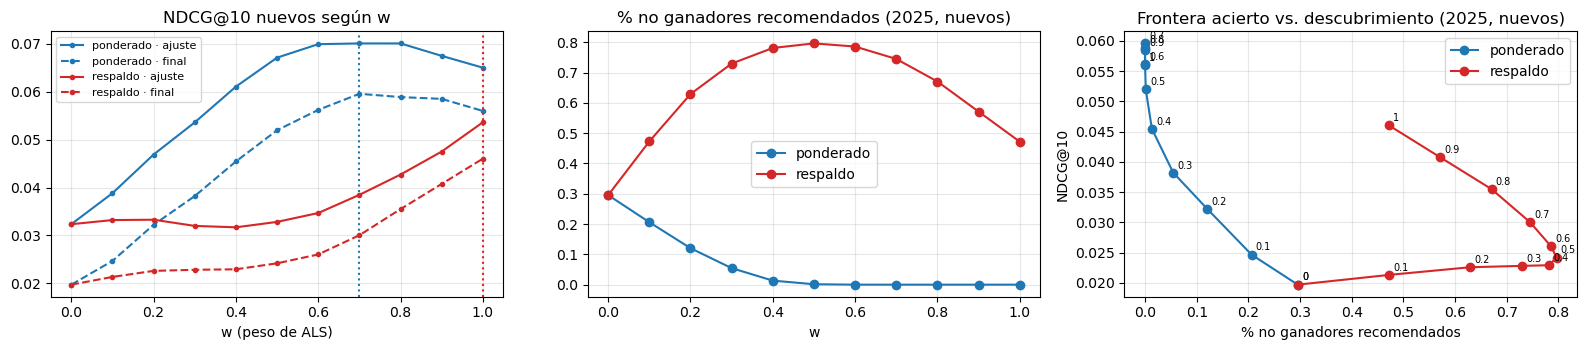

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
estilo = {"ponderado": "tab:blue", "respaldo": "tab:red"}
for v, col in estilo.items():
    for s, ls in [("ajuste", "-"), ("final", "--")]:
        d = curva[(curva.variante == v) & (curva.split == s) & (curva.regimen == "nuevos")]
        ax[0].plot(d.w, d.ndcg, ls, color=col, marker="o", ms=3, label=f"{v} · {s}")
    ax[0].axvline(WS[v], color=col, ls=":")
    d = curva[(curva.variante == v) & (curva.split == "final") & (curva.regimen == "nuevos")]
    ax[1].plot(d.w, d.pct_no_ganadores, "o-", color=col, label=v)
    ax[2].plot(d.pct_no_ganadores, d.ndcg, "o-", color=col, label=v)
    for _, r in d.iterrows():
        ax[2].annotate(f"{r.w:g}", (r.pct_no_ganadores, r.ndcg), textcoords="offset points", xytext=(3, 3), fontsize=7)
ax[0].set(title="NDCG@10 nuevos según w", xlabel="w (peso de ALS)"); ax[0].legend(fontsize=8)
ax[1].set(title="% no ganadores recomendados (2025, nuevos)", xlabel="w"); ax[1].legend()
ax[2].set(title="Frontera acierto vs. descubrimiento (2025, nuevos)", xlabel="% no ganadores recomendados", ylabel="NDCG@10"); ax[2].legend()
mostrar_fig("hibrido_w")

In [10]:
lineas = []
for v in VARIANTES:
    a, w = aj[v], WS[v]
    fi = curva[(curva.variante == v) & (curva.split == "final") & (curva.regimen == "nuevos")].set_index("w")
    lineas.append(
        f"- **{v}:** mejor w en ajuste = **{w:g}** (NDCG@10 nuevos {a.loc[w, 'ndcg']:.3f}; ALS solo {aj['ponderado'].loc[1.0, 'ndcg']:.3f}; "
        f"contenido solo {a.loc[0.0, 'ndcg']:.3f})" + ("" if 0 < w < 1 else " — ⚠ óptimo en un extremo"
        + (": con w = 1 los ganadores se ordenan solo por ALS y los no ganadores solo por contenido" if v == "respaldo" else "")) +
        f"; en 2025 el mejor sería w = {float(fi.ndcg.idxmax()):g} ({fi.loc[w, 'ndcg']:.3f} de {fi.ndcg.max():.3f} posible); "
        f"no ganadores recomendados: **{fi.loc[w, 'pct_no_ganadores']:.1%}**")
display(Markdown("\n".join(lineas)))

- **ponderado:** mejor w en ajuste = **0.7** (NDCG@10 nuevos 0.070; ALS solo 0.065; contenido solo 0.032); en 2025 el mejor sería w = 0.7 (0.060 de 0.060 posible); no ganadores recomendados: **0.0%**
- **respaldo:** mejor w en ajuste = **1** (NDCG@10 nuevos 0.054; ALS solo 0.065; contenido solo 0.032) — ⚠ óptimo en un extremo: con w = 1 los ganadores se ordenan solo por ALS y los no ganadores solo por contenido; en 2025 el mejor sería w = 1 (0.046 de 0.046 posible); no ganadores recomendados: **47.2%**

---
### **3. Evaluación en el hold-out 2025**

Siete modelos con los mismos candidatos y métricas: popularidad global, popularidad por familia, ALS, contenido (HNSW), **híbrido ponderado**, **híbrido con respaldo** (cada uno con su `w` calibrado) y RRF

In [11]:
c = ctx["final"]
modelos = {m: cands["final"][m] for m in ["popularidad_global", "popularidad_familia", "als", "contenido"]}
modelos["hibrido"] = hibrido("final", WS["ponderado"])
modelos["hibrido_respaldo"] = hibrido("final", WS["respaldo"], respaldo=True)
modelos["rrf"] = {reg: rankear_por(union[("final", reg)], "rrf") for reg in ["todos", "nuevos"]}
res = []
for m, cd in modelos.items():
    res += evaluar_modelo(c, m, cd, universos=("completo", "alcanzable"), conocidos=c.catalogo_keys)
res = pd.DataFrame(res)
cols = ["modelo", "precision", "recall", "ndcg", "map", "cobertura", "pct_cola_larga", "pct_no_ganadores", "popularidad_media"]
tabla = {}
for reg in ["nuevos", "todos"]:
    for k in KS:
        tabla[(reg, k)] = res[(res.regimen == reg) & (res.grupo == "todas") & (res.universo == "completo") & (res.k == k)][cols].round(4)
        print(f"régimen {reg}, K = {k}"); display(tabla[(reg, k)])

régimen nuevos, K = 5


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
0,popularidad_global,0.0149,0.0072,0.0170,0.0089,0.0001,0.0000,0.0000,155.7251
16,popularidad_familia,0.0231,0.0092,0.0274,0.0152,0.0046,0.0151,0.0000,52.6790
32,als,0.0506,0.0286,0.0601,0.0335,0.0120,0.0130,0.0000,30.6057
48,contenido,0.0192,0.0078,0.0202,0.0104,0.0177,0.1835,0.2816,6.3519
72,hibrido,0.0539,0.0304,0.0628,0.0353,0.0135,0.0217,0.0000,25.4826
88,hibrido_respaldo,0.0401,0.0225,0.0499,0.0282,0.0165,0.0061,0.4021,20.3066
104,rrf,0.0398,0.0200,0.0454,0.0252,0.0161,0.0518,0.0278,15.1534


régimen nuevos, K = 10


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
1,popularidad_global,0.0127,0.0116,0.0171,0.0072,0.0001,0.0000,0.0000,126.8135
17,popularidad_familia,0.0186,0.0137,0.0249,0.0107,0.0085,0.0191,0.0000,42.3981
33,als,0.0388,0.0392,0.0560,0.0256,0.0197,0.0224,0.0000,26.1336
49,contenido,0.0162,0.0129,0.0197,0.0077,0.0298,0.1860,0.2958,5.7729
73,hibrido,0.0421,0.0443,0.0596,0.0270,0.0215,0.0312,0.0000,21.6637
89,hibrido_respaldo,0.0310,0.0298,0.0460,0.0212,0.0280,0.0087,0.4721,15.7238
105,rrf,0.0345,0.0326,0.0452,0.0195,0.0257,0.0650,0.0546,14.7225


régimen todos, K = 5


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
8,popularidad_global,0.0326,0.0101,0.0394,0.0218,0.0000,0.0000,0.0000,159.2000
24,popularidad_familia,0.0724,0.0229,0.0845,0.0525,0.0041,0.0150,0.0000,59.3355
40,als,0.2031,0.0915,0.2377,0.1587,0.0133,0.0242,0.0000,32.3424
56,contenido,0.0510,0.0190,0.0582,0.0352,0.0183,0.1910,0.2427,7.3094
64,hibrido,0.1974,0.0931,0.2303,0.1532,0.0172,0.0496,0.0000,26.2181
80,hibrido_respaldo,0.1608,0.0691,0.1981,0.1294,0.0165,0.0141,0.3853,21.6231
96,rrf,0.1403,0.0616,0.1591,0.1031,0.0202,0.0882,0.0174,15.5762


régimen todos, K = 10


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
9,popularidad_global,0.0287,0.0160,0.0369,0.0156,0.0001,0.0000,0.0000,130.0000
25,popularidad_familia,0.0543,0.0320,0.0721,0.0360,0.0077,0.0190,0.0000,46.9996
41,als,0.1558,0.1232,0.2141,0.1218,0.0244,0.0471,0.0000,27.0874
57,contenido,0.0443,0.0315,0.0561,0.0272,0.0305,0.1909,0.2602,6.5663
65,hibrido,0.1512,0.1273,0.2096,0.1193,0.0295,0.0719,0.0000,22.3615
81,hibrido_respaldo,0.1228,0.0905,0.1754,0.0976,0.0293,0.0199,0.4652,16.3707
97,rrf,0.1160,0.0933,0.1511,0.0813,0.0320,0.0987,0.0402,14.7755


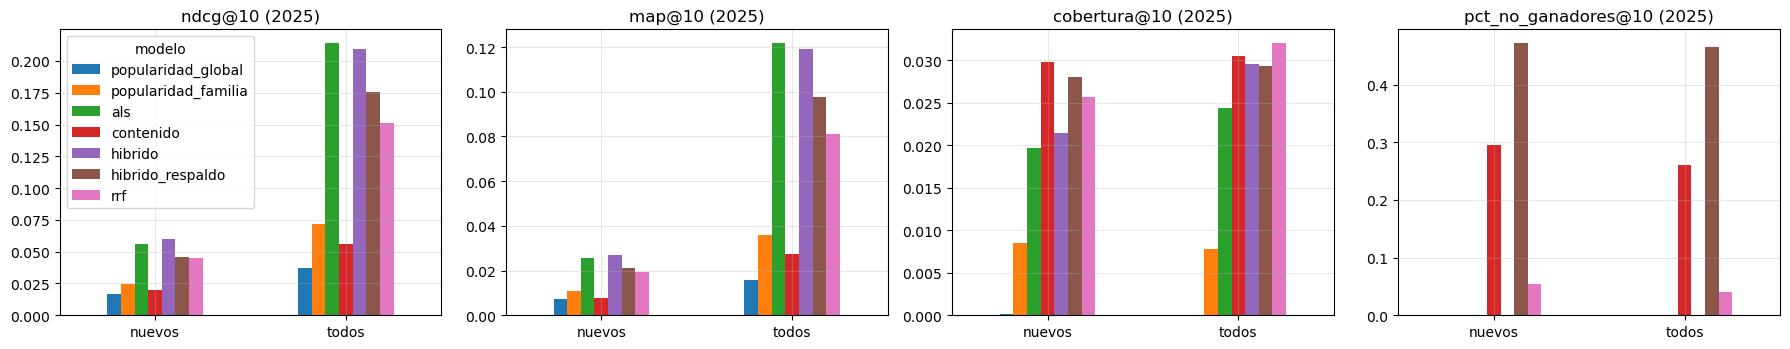

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
q = res[(res.grupo == "todas") & (res.universo == "completo") & (res.k == 10)]
orden = list(modelos)
for i, met in enumerate(["ndcg", "map", "cobertura", "pct_no_ganadores"]):
    q.pivot(index="regimen", columns="modelo", values=met)[orden].plot.bar(ax=ax[i], rot=0, legend=(i == 0))
    ax[i].set(title=f"{met}@10 (2025)", xlabel="")
mostrar_fig("final_modelos")

#### a. Intervalos de confianza

Diferencia pareada por entidad (bootstrap) de los híbridos y de RRF frente a ALS, en NDCG@10

In [13]:
ic = []
for reg in ["nuevos", "todos"]:
    v = {m: por_entidad(a_recs(modelos[m][reg]), c.verdad[reg], 10) for m in ["als", "hibrido", "hibrido_respaldo", "rrf", "contenido"]}
    for m in ["hibrido", "hibrido_respaldo", "rrf", "contenido"]:
        ic.append({"regimen": reg, "comparacion": f"{m} − als", **dict(zip(["media", "ic_inf", "ic_sup"], ic_bootstrap(v[m], v["als"])))})
ic = pd.DataFrame(ic).round(4)
ic

,regimen,comparacion,media,ic_inf,ic_sup
0,nuevos,hibrido − als,0.0036,0.0014,0.0056
1,nuevos,hibrido_respaldo − als,-0.0100,-0.0116,-0.0084
2,nuevos,rrf − als,-0.0108,-0.0145,-0.0072
3,nuevos,contenido − als,-0.0363,-0.0407,-0.0321
4,todos,hibrido − als,-0.0046,-0.0082,-0.0009
5,todos,hibrido_respaldo − als,-0.0387,-0.0415,-0.0361
6,todos,rrf − als,-0.0630,-0.0688,-0.0571
7,todos,contenido − als,-0.1580,-0.1652,-0.1504


#### b. ¿Dónde ayuda el contenido?

- Entidades agrupadas por **cuántos proveedores tuvieron en train** (terciles): donde ALS tiene poca historia, la matriz es más dispersa

- NDCG@10 en pares nuevos por grupo

In [14]:
grado = pd.Series({u: len(c.vistos_key.get(u, ())) for u in c.verdad["nuevos"]})
tercil = pd.qcut(grado.rank(method="first"), 3, labels=["poca historia", "media", "mucha historia"])
seg = []
for m in ["als", "contenido", "hibrido", "hibrido_respaldo", "rrf"]:
    recs = a_recs(modelos[m]["nuevos"])
    for t in tercil.cat.categories:
        ents = set(tercil[tercil == t].index)
        seg.append({"modelo": m, "grupo": t, "proveedores_train_mediana": int(grado[tercil == t].median()),
                    **evaluar(recs, {u: r for u, r in c.verdad["nuevos"].items() if u in ents}, 10)})
seg = pd.DataFrame(seg)
seg_p = seg.pivot(index="grupo", columns="modelo", values="ndcg").loc[tercil.cat.categories].round(4)
seg_p

modelo,als,contenido,hibrido,hibrido_respaldo,rrf
poca historia,0.0336,0.0098,0.0355,0.0271,0.0262
media,0.0539,0.0132,0.0598,0.0417,0.0395
mucha historia,0.0805,0.0359,0.0835,0.0692,0.0698


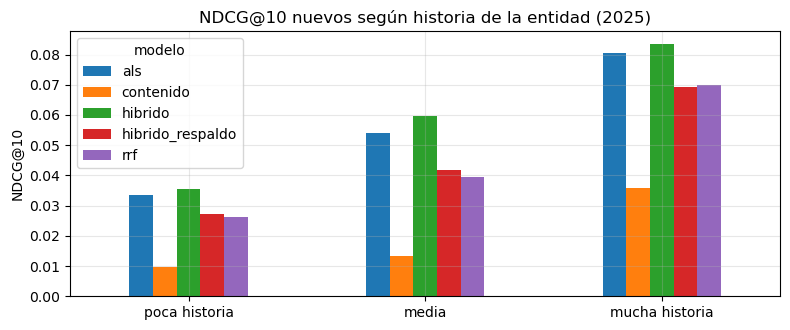

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.4))
seg_p[["als", "contenido", "hibrido", "hibrido_respaldo", "rrf"]].plot.bar(ax=ax, rot=0)
ax.set(title="NDCG@10 nuevos según historia de la entidad (2025)", xlabel="", ylabel="NDCG@10")
mostrar_fig("hibrido_por_historia")

#### c. Aciertos que suma el híbrido

Aciertos en pares nuevos (top-10) del híbrido que ALS **no** tenía, y cuántos son oferentes que nunca ganaron

In [16]:
def aciertos(cd, k=10):
    r = a_recs(cd["nuevos"]); out = set()
    for u, rel in c.verdad["nuevos"].items():
        out |= {(u, p) for p in r.get(u, [])[:k] if p in rel}
    return out

h = {m: aciertos(modelos[m]) for m in ["als", "contenido", "hibrido", "hibrido_respaldo", "rrf"]}
suma = pd.DataFrame([{"modelo": m, "aciertos": len(h[m]), "nuevos_vs_als": len(h[m] - h["als"]),
                      "perdidos_vs_als": len(h["als"] - h[m]),
                      "nuevos_vs_als_no_ganadores": sum(p in c.no_ganadores for _, p in h[m] - h["als"])} for m in h])
suma

,modelo,aciertos,nuevos_vs_als,perdidos_vs_als,nuevos_vs_als_no_ganadores
0,als,1013,0,0,0
1,contenido,423,331,921,77
2,hibrido,1099,282,196,0
3,hibrido_respaldo,808,80,285,80
4,rrf,900,412,525,16


#### d. Entidades cautivas (PQ3.1)

In [17]:
caut = res[(res.regimen == "nuevos") & (res.universo == "completo") & (res.k == 10)].pivot_table(
    index="modelo", columns="grupo", values=["ndcg", "recall"]).loc[orden].round(4)
caut

ndcg           recall        
grupo               cautivas   todas cautivas   todas
modelo                                               
popularidad_global    0.0138  0.0171   0.0145  0.0116
popularidad_familia   0.0128  0.0249   0.0120  0.0137
als                   0.0419  0.0560   0.0418  0.0392
contenido             0.0108  0.0197   0.0124  0.0129
hibrido               0.0458  0.0596   0.0499  0.0443
hibrido_respaldo      0.0330  0.0460   0.0295  0.0298
rrf                   0.0293  0.0452   0.0337  0.0326

---
### **4. Respuesta a PQ3.2**

In [18]:
t10 = tabla[("nuevos", 10)].set_index("modelo"); d = ic[ic.regimen == "nuevos"].set_index("comparacion")
s_ = suma.set_index("modelo")
mejor = t10.ndcg.idxmax()
sig = lambda k: ("significativa" if d.loc[k, "ic_inf"] > 0 else "significativamente peor" if d.loc[k, "ic_sup"] < 0 else "no significativa")
poca = seg_p.loc["poca historia"]
display(Markdown(
    f"- **Mejor modelo en pares nuevos de 2025: `{mejor}`** (NDCG@10 {t10.loc[mejor, 'ndcg']:.3f}; MAP@10 {t10.loc[mejor, 'map']:.3f})\n"
    f"- **Híbrido (w = {W:g}) vs. ALS:** NDCG@10 {t10.loc['hibrido', 'ndcg']:.3f} vs. {t10.loc['als', 'ndcg']:.3f}; diferencia "
    f"{d.loc['hibrido − als', 'media']:+.4f}, IC 95% [{d.loc['hibrido − als', 'ic_inf']:+.4f}, {d.loc['hibrido − als', 'ic_sup']:+.4f}] → {sig('hibrido − als')}\n"
    f"- **RRF vs. ALS:** {d.loc['rrf − als', 'media']:+.4f}, IC 95% [{d.loc['rrf − als', 'ic_inf']:+.4f}, {d.loc['rrf − als', 'ic_sup']:+.4f}] → {sig('rrf − als')}\n"
    f"- **Sesgo de popularidad:** popularidad media de lo recomendado {t10.loc['als', 'popularidad_media']:.1f} (ALS) → "
    f"{t10.loc['hibrido', 'popularidad_media']:.1f} (híbrido); cobertura {t10.loc['als', 'cobertura']:.2%} → {t10.loc['hibrido', 'cobertura']:.2%}; "
    f"no ganadores {t10.loc['als', 'pct_no_ganadores']:.1%} → **{t10.loc['hibrido', 'pct_no_ganadores']:.1%}**\n"
    f"- **Aciertos:** el híbrido acierta {s_.loc['hibrido', 'aciertos']:,} pares nuevos; {s_.loc['hibrido', 'nuevos_vs_als']:,} no los tenía ALS "
    f"({s_.loc['hibrido', 'nuevos_vs_als_no_ganadores']:,} de oferentes que nunca ganaron) y pierde {s_.loc['hibrido', 'perdidos_vs_als']:,} de ALS\n"
    f"- **Entidades con poca historia:** ALS {poca['als']:.3f}, contenido {poca['contenido']:.3f}, híbrido {poca['hibrido']:.3f}, "
    f"con respaldo {poca['hibrido_respaldo']:.3f}\n"
    f"- **Con respaldo por contenido (w = {WS['respaldo']:g}) vs. ALS:** NDCG@10 {t10.loc['hibrido_respaldo', 'ndcg']:.3f}; diferencia "
    f"{d.loc['hibrido_respaldo − als', 'media']:+.4f}, IC 95% [{d.loc['hibrido_respaldo − als', 'ic_inf']:+.4f}, "
    f"{d.loc['hibrido_respaldo − als', 'ic_sup']:+.4f}] → {sig('hibrido_respaldo − als')}; "
    f"no ganadores recomendados **{t10.loc['hibrido_respaldo', 'pct_no_ganadores']:.1%}**; "
    f"aciertos de no ganadores que ALS no tenía: **{s_.loc['hibrido_respaldo', 'nuevos_vs_als_no_ganadores']:,}**"))

- **Mejor modelo en pares nuevos de 2025: `hibrido`** (NDCG@10 0.060; MAP@10 0.027)
- **Híbrido (w = 0.7) vs. ALS:** NDCG@10 0.060 vs. 0.056; diferencia +0.0036, IC 95% [+0.0014, +0.0056] → significativa
- **RRF vs. ALS:** -0.0108, IC 95% [-0.0145, -0.0072] → significativamente peor
- **Sesgo de popularidad:** popularidad media de lo recomendado 26.1 (ALS) → 21.7 (híbrido); cobertura 1.97% → 2.15%; no ganadores 0.0% → **0.0%**
- **Aciertos:** el híbrido acierta 1,099 pares nuevos; 282 no los tenía ALS (0 de oferentes que nunca ganaron) y pierde 196 de ALS
- **Entidades con poca historia:** ALS 0.034, contenido 0.010, híbrido 0.035, con respaldo 0.027
- **Con respaldo por contenido (w = 1) vs. ALS:** NDCG@10 0.046; diferencia -0.0100, IC 95% [-0.0116, -0.0084] → significativamente peor; no ganadores recomendados **47.2%**; aciertos de no ganadores que ALS no tenía: **80**

---
### **5. Escritura de datos**

- `temp/datos/final_cand_hibrido{,_respaldo}`: top-`N_CAND` de cada híbrido calibrado (entrada de `e_analisis_sustitutos`)

- `temp/datos/final_union`: candidatos con puntajes normalizados de ALS y contenido (para recombinar con cualquier `w`)

In [19]:
for m in ["hibrido", "hibrido_respaldo"]:
    pd.concat([d.assign(regimen=reg) for reg, d in modelos[m].items()]).to_parquet(datos_dir / f"final_cand_{m}", index=False)
pd.concat([union[("final", reg)].assign(regimen=reg) for reg in ["todos", "nuevos"]]).drop(columns="h", errors="ignore") \
  .to_parquet(datos_dir / "final_union", index=False)

---
### **6. Artefactos para la app web (Parte VII)**

`temp/artefactos_web/`, livianos y con nombres legibles:

| Archivo | Contenido |
|---|---|
| `recomendaciones.parquet` | top-10 por entidad, régimen, variante (`ponderado` / `respaldo`) y `w` ∈ `W_WEB`, con nombre del proveedor, puntajes de ALS y contenido, y si nunca ganó |
| `entidades.parquet` | entidades evaluables: nombre, región, HHI de train, cautiva |
| `curva_w.parquet` | métricas según `w` (ajuste y 2025) |
| `metricas_modelos.parquet` | tabla final de los seis modelos |
| `factores_2d.parquet` | factores de ALS de entidades y proveedores proyectados a 2D (SVD) |

In [20]:
web = Path.cwd() / "temp" / "artefactos_web"; web.mkdir(parents=True, exist_ok=True)
dim_p = leer(final_dir, "proveedores").select("proveedor_key", F.col("nombre").alias("proveedor"), F.col("region").alias("region_proveedor")).toPandas()
dim_e = leer(final_dir, "entidades").select("entidad_key", F.col("nombre").alias("entidad"), "region").toPandas()

recs_web = []
for reg in ["todos", "nuevos"]:
    u = union[("final", reg)]
    for var, resp in VARIANTES.items():
        for w in W_WEB:
            u["h"] = puntaje_hibrido(u, w, resp)
            t = u.sort_values(["entidad_key", "h"], ascending=[True, False]).groupby("entidad_key").head(10).copy()
            t["rank"] = t.groupby("entidad_key").cumcount() + 1
            recs_web.append(t.assign(w=w, regimen=reg, variante=var)[["entidad_key", "regimen", "variante", "w", "rank", "proveedor_key",
                                                                     "h", "n_als", "n_cb", "origen"]])
recs_web = (pd.concat(recs_web).merge(dim_p, on="proveedor_key", how="left")
            .assign(nunca_gano=lambda d: d.proveedor_key.isin(c.no_ganadores).astype(int),
                    acierto_2025=lambda d: [int(p in c.verdad[r].get(u, ())) for u, p, r in zip(d.entidad_key, d.proveedor_key, d.regimen)]))
recs_web.to_parquet(web / "recomendaciones.parquet", index=False)

c.evaluables.merge(dim_e, on="entidad_key", how="left")[["entidad_key", "entidad", "region", "hhi_train", "cautiva", "relevantes", "relevantes_nuevos"]] \
  .to_parquet(web / "entidades.parquet", index=False)
curva.to_parquet(web / "curva_w.parquet", index=False)
res.to_parquet(web / "metricas_modelos.parquet", index=False)

U, V, ie, ip = als_f["final"]
from sklearn.decomposition import TruncatedSVD
p2 = TruncatedSVD(2, random_state=SEED).fit(np.vstack([U, V]))
top_p = c.catalogo.nlargest(3000, "popularidad").proveedor_key
f2 = pd.concat([pd.DataFrame(p2.transform(U), columns=["x", "y"]).assign(tipo="entidad", key=c.key_e),
                pd.DataFrame(p2.transform(V[ip[top_p].to_numpy()]), columns=["x", "y"]).assign(tipo="proveedor", key=top_p.to_numpy())])
f2.to_parquet(web / "factores_2d.parquet", index=False)
pd.DataFrame([{"archivo": p.name, "mb": round(p.stat().st_size / 1024**2, 2)} for p in sorted(web.glob("*.parquet"))])

,archivo,mb
0,curva_w.parquet,0.01
1,entidades.parquet,0.10
2,factores_2d.parquet,0.11
3,metricas_modelos.parquet,0.01
4,recomendaciones.parquet,8.25


#### a. Verificación

In [21]:
r = pd.read_parquet(web / "recomendaciones.parquet")
assert r.groupby(["entidad_key", "regimen", "variante", "w"]).size().max() <= 10
assert set(r.w.unique()) == set(W_WEB) and r.proveedor.notna().mean() > .99
for m in ["hibrido", "hibrido_respaldo"]:
    h = pd.read_parquet(datos_dir / f"final_cand_{m}")
    nue = h[h.regimen == "nuevos"]
    assert not any(p in c.vistos_key.get(u, ()) for u, p in zip(nue.entidad_key, nue.proveedor_key)), m
# con w = 1 y w = 0 el top-10 del híbrido coincide con el orden de cada componente dentro de la unión
for w, col in [(1.0, "n_als"), (0.0, "n_cb")]:
    x = r[(r.w == w) & (r.regimen == "nuevos") & (r.variante == "ponderado")]
    assert (x.groupby("entidad_key")[col].apply(lambda s: s.is_monotonic_decreasing)).all(), w
print(f"OK | {len(r):,} recomendaciones web, {r.entidad_key.nunique():,} entidades | peso total {sum(p.stat().st_size for p in web.glob('*')) / 1024**2:.1f} MB")

OK | 534,400 recomendaciones web, 2,672 entidades | peso total 8.5 MB


### **7. Escritura de resultados**

In [22]:
escritos = guardar_tablas({"origen_candidatos": origen, "curva_w": curva, "evaluacion_final": res, "ic_vs_als": ic,
                           "por_historia": seg, "aciertos_sumados": suma})

Escrito en 03_Recomendacion/temp/d_hibrido_evaluacion/: origen_candidatos, curva_w, evaluacion_final, ic_vs_als, por_historia, aciertos_sumados


#### a. Verificación

In [23]:
verificar_salidas(escritos)

OK: 6 tablas (parquet + json) | 3 figuras: final_modelos, hibrido_por_historia, hibrido_w


---
### **8. Cerrar sesión**

In [24]:
spark.stop()